In [1]:
# Random Forest

In [2]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
)

In [3]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd

PROJECT_DIR = (
    Path.home()
    / "Downloads"
    / "IDX-Exchange-Data-Science"
)

# Load features and targets prepared in notebook 03.
prepared_data = joblib.load(
    PROJECT_DIR / "prepared_modeling_data.joblib"
)

X_train_ready = prepared_data["X_train_ready"]
X_test_ready = prepared_data["X_test_ready"]
y_train = prepared_data["y_train"]
y_test = prepared_data["y_test"]

print("Training matrix:", X_train_ready.shape)
print("Test matrix:", X_test_ready.shape)

Training matrix: (278710, 16661)
Test matrix: (11684, 16661)


In [4]:
from sklearn.ensemble import RandomForestRegressor

# Train a random forest on log sale prices.
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=5,
    max_features=0.3,
    random_state=42,
    n_jobs=-1,
)

print("Training Random Forest...", flush=True)
rf_model.fit(X_train_ready, np.log(y_train))

# Convert predictions back to dollars.
rf_predictions = np.exp(
    rf_model.predict(X_test_ready)
)

# Display test metrics in dollars.
rf_metrics_df = pd.DataFrame({
    f"Random Forest — Test metrics (n = {len(y_test):,})": [
        "R² (price)",
        "MAE",
        "RMSE",
        "MAPE",
    ],
    "Value": [
        f"{r2_score(y_test, rf_predictions):.4f}",
        f"${mean_absolute_error(y_test, rf_predictions):,.2f}",
        f"${np.sqrt(mean_squared_error(y_test, rf_predictions)):,.2f}",
        f"{mean_absolute_percentage_error(y_test, rf_predictions) * 100:.2f}%",
    ],
})

display(rf_metrics_df.style.hide(axis="index"))

Training Random Forest...


"Random Forest — Test metrics (n = 11,684)",Value
R² (price),0.7708
MAE,"$190,535.11"
RMSE,"$522,371.80"
MAPE,13.21%


In [5]:
# Compare training and test performance without retraining.
rows = []

for split, features, actual in [
    ("Train", X_train_ready, y_train),
    ("Test", X_test_ready, y_test),
]:
    predicted = np.exp(rf_model.predict(features))

    rows.append({
        "Split": split,
        "R² (price)": r2_score(actual, predicted),
        "MAE ($)": mean_absolute_error(actual, predicted),
        "RMSE ($)": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE (%)": (
            mean_absolute_percentage_error(actual, predicted) * 100
        ),
    })

display(
    pd.DataFrame(rows).style
    .hide(axis="index")
    .format({
        "R² (price)": "{:.4f}",
        "MAE ($)": "{:,.2f}",
        "RMSE ($)": "{:,.2f}",
        "MAPE (%)": "{:.2f}",
    })
)

Split,R² (price),MAE ($),RMSE ($),MAPE (%)
Train,0.3825,"151,713.68","1,180,239.90",11.18
Test,0.7708,"190,535.11","522,371.80",13.21


In [6]:
# Inspect the training target distribution.
display(
    y_train.describe(
        percentiles=[0.01, 0.5, 0.95, 0.99, 0.999]
    ).to_frame("Training ClosePrice")
)

display(
    y_train.nlargest(10).to_frame("Largest training prices")
)

display(
    y_train.nsmallest(10).to_frame("Smallest training prices")
)

,Training ClosePrice
count,2.787100e+05
mean,1.190882e+06
std,1.501973e+06
min,8.000000e+03
1%,2.500000e+05
50%,8.900000e+05
95%,2.910000e+06
99%,5.000000e+06
99.9%,1.010657e+07
max,4.720000e+08


,Largest training prices
257986,472000000.0
242562,199947850.0
83101,178000000.0
89752,142590000.0
120781,131588800.0
212543,105800888.0
131025,90500000.0
77057,35000000.0
77015,29550000.0
156474,29000000.0


,Smallest training prices
264477,8000.0
259418,8300.0
31820,13400.0
76200,14900.0
163047,16000.0
267806,18000.0
166251,18380.0
68449,19500.0
110715,20000.0
49810,20100.0


In [7]:
from pathlib import Path

# Get prices from the 10 highest and 10 lowest training records.
prices_to_check = pd.concat([
    y_train.nlargest(10),
    y_train.nsmallest(10),
]).unique()

RAW_DIR = Path.home() / "Downloads" / "idx exchange" / "csv"

# Include all monthly files, including filled files.
files = sorted(RAW_DIR.glob("CRMLSSold*.csv"))

if not files:
    raise FileNotFoundError(f"No matching CSV files found in {RAW_DIR}")

columns_to_check = [
    "ListingKey",
    "ListingId",
    "UnparsedAddress",
    "City",
    "StateOrProvince",
    "PostalCode",
    "PropertyType",
    "PropertySubType",
    "LivingArea",
    "CloseDate",
    "ClosePrice",
    "ListPrice",
    "OriginalListPrice",
]

matches = []

for file in files:
    for chunk in pd.read_csv(
        file,
        usecols=lambda col: col in columns_to_check,
        dtype="string",
        chunksize=50000,
    ):
        # Parse prices and sale dates for filtering.
        prices = pd.to_numeric(
            chunk["ClosePrice"]
            .str.replace(",", "", regex=False)
            .str.replace("$", "", regex=False),
            errors="coerce",
        )

        close_dates = pd.to_datetime(
            chunk["CloseDate"], errors="coerce"
        )

        # Require all conditions:
        # 1. A price among the selected training extremes.
        # 2. Residential property.
        # 3. Single-family residence.
        # 4. Located in California.
        # 5. Sold before the April 2026 test period.
        mask = (
            prices.isin(prices_to_check)
            & chunk["PropertyType"].eq("Residential")
            & chunk["PropertySubType"].eq("SingleFamilyResidence")
            & chunk["StateOrProvince"].eq("CA")
            & close_dates.lt(pd.Timestamp("2026-04-01"))
        ).fillna(False)

        matched = chunk.loc[mask].copy()

        if not matched.empty:
            matched["ClosePrice"] = prices.loc[mask]
            matched.insert(0, "SourceFile", file.name)
            matches.append(matched)

if matches:
    training_candidates = (
        pd.concat(matches, ignore_index=True)
        .sort_values("ClosePrice")
        .reset_index(drop=True)
    )

    with pd.option_context(
        "display.max_rows", None,
        "display.max_columns", None,
        "display.max_colwidth", None,
    ):
        display(training_candidates)

    print("Candidate records:", len(training_candidates))

else:
    training_candidates = pd.DataFrame()
    print("No matching candidate records found.")

,SourceFile,OriginalListPrice,ListingKey,CloseDate,ClosePrice,UnparsedAddress,PropertyType,LivingArea,ListPrice,PropertySubType,ListingId,City,StateOrProvince,PostalCode
0,CRMLSSold202602.csv,8000.0,1147508351,2026-02-04,8000.0,12221 C Street,Residential,984.0,8000.0,SingleFamilyResidence,SW25271272,Trona,CA,93562
1,CRMLSSold202601.csv,2199000.0,1110035161,2026-01-17,8300.0,3710 Sunset Ridge Road,Residential,3886.0,2000000.0,SingleFamilyResidence,P1-21547,Altadena,CA,91001
2,CRMLSSold202404_filled.csv,20000.0,1063025602,2024-04-27,13400.0,13285 Lupine Street,Residential,1104.0,20000.0,SingleFamilyResidence,MB24027379,Trona,CA,93562
3,CRMLSSold202407_filled.csv,20000.0,1063025602,2024-07-09,14900.0,13285 Lupine Street,Residential,1104.0,20000.0,SingleFamilyResidence,MB24027379,Trona,CA,93562
4,CRMLSSold202504.csv,1799100.0,1107291928,2025-04-10,16000.0,22120 Costanso Street,Residential,2088.0,1599000.0,SingleFamilyResidence,SR25035806,Woodland Hills,CA,91364
5,CRMLSSold202602.csv,28000.0,1108190915,2026-02-11,18000.0,18250 Palowalla Road,Residential,1488.0,22000.0,SingleFamilyResidence,OC25044942,Blythe,CA,92225
6,CRMLSSold202504.csv,1949000.0,1098673716,2025-04-10,18380.0,19036 Brittany Place,Residential,3352.0,1849000.0,SingleFamilyResidence,TR24247403,Rowland Heights,CA,91748
7,CRMLSSold202407_filled.csv,170000.0,1076223228,2024-07-31,19500.0,830 Las Amigas Drive,Residential,1686.0,170000.0,SingleFamilyResidence,HD24116439,Barstow,CA,92311
8,CRMLSSold202411.csv,20000.0,1093726760,2024-11-27,20000.0,12168 B Street,Residential,739.0,20000.0,SingleFamilyResidence,OC24227676,Trona,CA,93562
9,CRMLSSold202405_filled.csv,40000.0,1061960016,2024-05-08,20100.0,416 N K Street,Residential,798.0,22500.0,SingleFamilyResidence,JT24043728,Needles,CA,92363


Candidate records: 27


In [8]:
# Evaluate the existing model on the log-price scale.
log_r2_rows = []

for split, features, actual in [
    ("Train", X_train_ready, y_train),
    ("Test", X_test_ready, y_test),
]:
    log_predictions = rf_model.predict(features)

    log_r2_rows.append({
        "Split": split,
        "R² (log price)": r2_score(
            np.log(actual),
            log_predictions,
        ),
    })

display(
    pd.DataFrame(log_r2_rows)
    .style.hide(axis="index")
    .format({"R² (log price)": "{:.4f}"})
)

Split,R² (log price)
Train,0.9323
Test,0.9114


### Random Forest Evaluation: Price and Log Scales

The Random Forest was trained on log-transformed sale prices. The same model was evaluated on two scales:

| Evaluation scale | Train R² | Test R² |
|---|---:|---:|
| Original price ($), after exponentiating predictions | 0.3825 | 0.7708 |
| Log price | 0.9323 | 0.9114 |

The small train–test gap on the log scale suggests limited overfitting under this metric. On the dollar scale, large absolute errors receive much greater weight. Remaining suspicious training prices may contribute to the low training R² and require further verification.

These scores measure different outcomes and should not be compared directly across scales. A log-scale R² of 0.9114 does not mean that price predictions are 91.14% accurate.

Next, maximum tree depth will be selected using a chronological validation split within the existing training data. April 2026 will remain the held-out test month. Preprocessing will be fitted on the fitting subset only. Training and validation R² will be plotted against maximum depth, using dollar-scale validation R² for parameter selection to match the final price evaluation.

### Selecting Maximum Tree Depth Using Validation R²

The existing training data is split chronologically: records before March 2026 are used for fitting, and March 2026 is reserved for validation. Random Forest models are trained on log prices with maximum depths of 8, 12, 16, and 20, while other parameters remain fixed. Training and validation R² are plotted on both dollar and log scales. The depth with the highest dollar-scale validation R² is selected; April 2026 test data is not used for parameter selection.

Encoding and scaling are refitted on the fitting subset only. This preliminary comparison retains the earlier missing-value treatment from Notebook 02.

Fitting records: 267,859
Validation records: 10,851
Training max_depth=8 ...
Done: Train R²=0.2616, Validation R²=0.5633
Training max_depth=12 ...
Done: Train R²=0.3225, Validation R²=0.6965
Training max_depth=16 ...
Done: Train R²=0.3564, Validation R²=0.7625
Training max_depth=20 ...
Done: Train R²=0.3733, Validation R²=0.7934


max_depth,Train R² (price),Validation R² (price),Train R² (log price),Validation R² (log price)
8,0.2616,0.5633,0.7645,0.7534
12,0.3225,0.6965,0.8628,0.8513
16,0.3564,0.7625,0.9079,0.8918
20,0.3733,0.7934,0.9332,0.9119


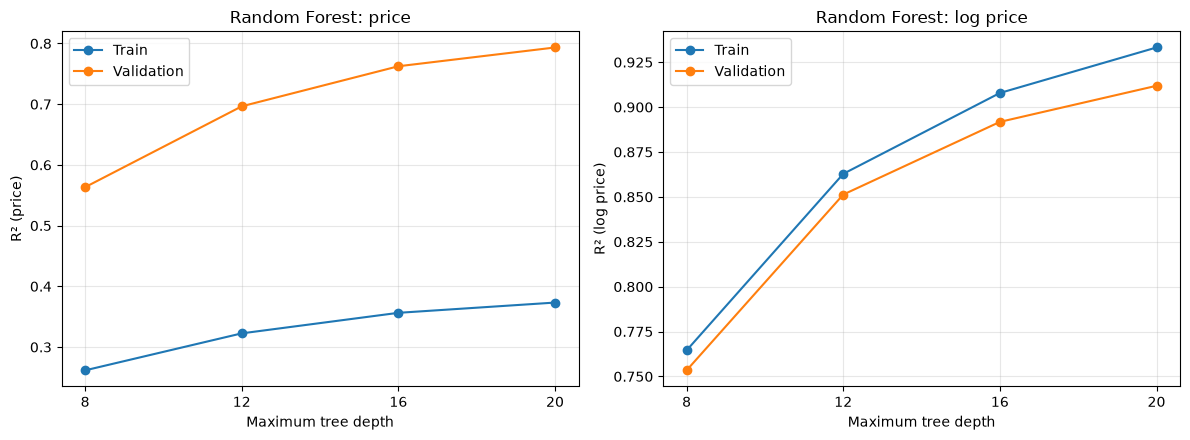

Best max_depth among tested values: 20
Best validation R² (price): 0.7934


In [9]:
from pathlib import Path
from sklearn.base import clone
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import joblib

PROJECT_DIR = (
    Path.home()
    / "Downloads"
    / "IDX-Exchange-Data-Science"
)

# Load the existing training data only.
depth_data = pd.read_csv(
    PROJECT_DIR / "single_family_train_cleaned.csv",
    dtype={"PostalCode": "string"},
    low_memory=False,
)

depth_dates = pd.to_datetime(
    depth_data["CloseDate"],
    errors="raise",
)

fit_mask = depth_dates.lt("2026-03-01")
val_mask = (
    depth_dates.ge("2026-03-01")
    & depth_dates.lt("2026-04-01")
)

if not fit_mask.any() or not val_mask.any():
    raise ValueError("The fitting or validation subset is empty.")

depth_X = depth_data.drop(
    columns=["ClosePrice", "CloseDate"]
).copy()

depth_y = pd.to_numeric(
    depth_data["ClosePrice"],
    errors="raise",
)

assert np.isfinite(depth_y).all() and depth_y.gt(0).all()

# Reuse the preprocessing configuration from Notebook 03.
# clone() removes the previously fitted rules.
depth_artifacts = joblib.load(
    PROJECT_DIR / "prepared_modeling_data.joblib"
)

depth_preprocessor = clone(depth_artifacts["preprocessor"])

category_columns = next(
    columns
    for name, transformer, columns
    in depth_preprocessor.transformers
    if name == "categorical"
)

# Apply the same fixed category-label cleanup as Notebook 03.
for col in category_columns:
    depth_X[col] = (
        depth_X[col]
        .astype("string")
        .str.strip()
        .str.lower()
        .replace("", pd.NA)
        .fillna("unknown")
    )

# Fit encoding and scaling on the earlier subset only.
depth_X_fit = depth_preprocessor.fit_transform(
    depth_X.loc[fit_mask]
)
depth_X_val = depth_preprocessor.transform(
    depth_X.loc[val_mask]
)

depth_y_fit = depth_y.loc[fit_mask].to_numpy(dtype=float)
depth_y_val = depth_y.loc[val_mask].to_numpy(dtype=float)

print(f"Fitting records: {len(depth_y_fit):,}", flush=True)
print(f"Validation records: {len(depth_y_val):,}", flush=True)

# Keep the existing RF settings; vary maximum depth only.
depth_choices = [8, 12, 16, 20]
depth_rows = []

for depth in depth_choices:
    print(f"Training max_depth={depth} ...", flush=True)

    candidate_model = clone(rf_model).set_params(
        max_depth=depth,
        verbose=0,
    )

    candidate_model.fit(
        depth_X_fit,
        np.log(depth_y_fit),
    )

    fit_log_predictions = candidate_model.predict(depth_X_fit)
    val_log_predictions = candidate_model.predict(depth_X_val)

    fit_r2 = r2_score(
        depth_y_fit,
        np.exp(fit_log_predictions),
    )
    val_r2 = r2_score(
        depth_y_val,
        np.exp(val_log_predictions),
    )

    depth_rows.append({
        "max_depth": depth,
        "Train R² (price)": fit_r2,
        "Validation R² (price)": val_r2,
        "Train R² (log price)": r2_score(
            np.log(depth_y_fit),
            fit_log_predictions,
        ),
        "Validation R² (log price)": r2_score(
            np.log(depth_y_val),
            val_log_predictions,
        ),
    })

    print(
        f"Done: Train R²={fit_r2:.4f}, "
        f"Validation R²={val_r2:.4f}",
        flush=True,
    )

depth_results = pd.DataFrame(depth_rows)

display(
    depth_results.style
    .hide(axis="index")
    .format({
        col: "{:.4f}"
        for col in depth_results.columns
        if col != "max_depth"
    })
)

# Plot both evaluation scales separately.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, scale in zip(axes, ["price", "log price"]):
    ax.plot(
        depth_results["max_depth"],
        depth_results[f"Train R² ({scale})"],
        marker="o",
        label="Train",
    )
    ax.plot(
        depth_results["max_depth"],
        depth_results[f"Validation R² ({scale})"],
        marker="o",
        label="Validation",
    )
    ax.set_xlabel("Maximum tree depth")
    ax.set_ylabel(f"R² ({scale})")
    ax.set_title(f"Random Forest: {scale}")
    ax.set_xticks(depth_choices)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

# Select depth using dollar-scale validation R².
best_depth_row = depth_results.loc[
    depth_results["Validation R² (price)"].idxmax()
]

best_max_depth = int(best_depth_row["max_depth"])

print(f"Best max_depth among tested values: {best_max_depth}")
print(
    "Best validation R² (price): "
    f"{best_depth_row['Validation R² (price)']:.4f}"
)

### Summary

The Random Forest achieved a training log-scale R² of 0.9323 and a test log-scale R² of 0.9114, indicating strong performance with a small generalization gap. Dollar-scale test R² was 0.7708, with a MAPE of 13.21%; remaining suspicious prices require further review.

Among the tested maximum depths (8, 12, 16, and 20), depth 20 produced the highest validation R²: 0.7934 on the dollar scale and 0.9119 on the log scale. Validation performance continued to improve with depth, supporting further evaluation of deeper trees.

Training Decision Tree: max_depth=8 ...
Validation R² (price): 0.5791
Training Decision Tree: max_depth=12 ...
Validation R² (price): 0.7218
Training Decision Tree: max_depth=16 ...
Validation R² (price): 0.7871
Training Decision Tree: max_depth=20 ...
Validation R² (price): 0.8070


max_depth,Train R² (price),Validation R² (price),Train R² (log price),Validation R² (log price)
8,0.2566,0.5791,0.7672,0.7645
12,0.3268,0.7218,0.8729,0.8633
16,0.3705,0.7871,0.9220,0.8933
20,0.3950,0.8070,0.9465,0.9008


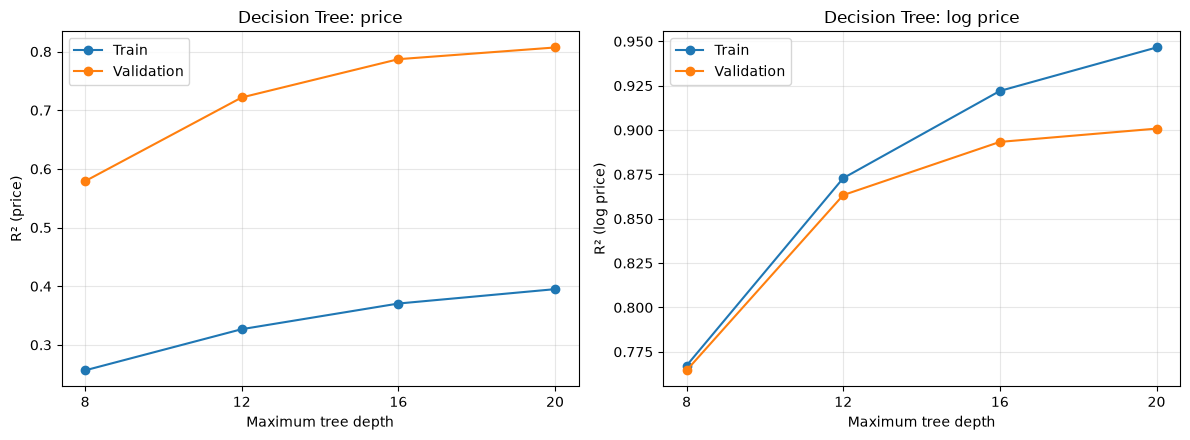

Best tested Decision Tree depth: 20
Best validation R² (price): 0.8070


In [10]:
from sklearn.tree import DecisionTreeRegressor

# Compare decision-tree depths using the same validation split.
dt_depth_choices = [8, 12, 16, 20]
dt_rows = []

for depth in dt_depth_choices:
    print(f"Training Decision Tree: max_depth={depth} ...", flush=True)

    dt_candidate = DecisionTreeRegressor(
        max_depth=depth,
        min_samples_leaf=5,
        random_state=42,
    )

    dt_candidate.fit(
        depth_X_fit,
        np.log(depth_y_fit),
    )

    fit_log_pred = dt_candidate.predict(depth_X_fit)
    val_log_pred = dt_candidate.predict(depth_X_val)

    dt_rows.append({
        "max_depth": depth,
        "Train R² (price)": r2_score(
            depth_y_fit,
            np.exp(fit_log_pred),
        ),
        "Validation R² (price)": r2_score(
            depth_y_val,
            np.exp(val_log_pred),
        ),
        "Train R² (log price)": r2_score(
            np.log(depth_y_fit),
            fit_log_pred,
        ),
        "Validation R² (log price)": r2_score(
            np.log(depth_y_val),
            val_log_pred,
        ),
    })

    print(
        "Validation R² (price): "
        f"{dt_rows[-1]['Validation R² (price)']:.4f}",
        flush=True,
    )

dt_depth_results = pd.DataFrame(dt_rows)

display(
    dt_depth_results.style
    .hide(axis="index")
    .format({
        col: "{:.4f}"
        for col in dt_depth_results.columns
        if col != "max_depth"
    })
)

# Plot training and validation performance on both scales.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, scale in zip(axes, ["price", "log price"]):
    for split in ["Train", "Validation"]:
        ax.plot(
            dt_depth_results["max_depth"],
            dt_depth_results[f"{split} R² ({scale})"],
            marker="o",
            label=split,
        )

    ax.set_xlabel("Maximum tree depth")
    ax.set_ylabel(f"R² ({scale})")
    ax.set_title(f"Decision Tree: {scale}")
    ax.set_xticks(dt_depth_choices)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

# Select depth using dollar-scale validation R².
dt_best_row = dt_depth_results.loc[
    dt_depth_results["Validation R² (price)"].idxmax()
]

dt_best_depth = int(dt_best_row["max_depth"])

print(f"Best tested Decision Tree depth: {dt_best_depth}")
print(
    "Best validation R² (price): "
    f"{dt_best_row['Validation R² (price)']:.4f}"
)

In [11]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error,
)

# Fit the selected tree on the full training set.
dt_model = DecisionTreeRegressor(
    max_depth=dt_best_depth,
    min_samples_leaf=5,
    random_state=42,
)

dt_model.fit(X_train_ready, np.log(y_train))

# Evaluate on both dollar and log scales.
dt_metrics_rows = []

for split, features, actual in [
    ("Train", X_train_ready, y_train),
    ("Test", X_test_ready, y_test),
]:
    log_predicted = dt_model.predict(features)
    predicted = np.exp(log_predicted)

    dt_metrics_rows.append({
        "Split": split,
        "R² (price)": r2_score(actual, predicted),
        "R² (log price)": r2_score(
            np.log(actual),
            log_predicted,
        ),
        "MAE ($)": mean_absolute_error(actual, predicted),
        "RMSE ($)": np.sqrt(
            mean_squared_error(actual, predicted)
        ),
        "MAPE (%)": (
            mean_absolute_percentage_error(actual, predicted)
            * 100
        ),
    })

dt_metrics_df = pd.DataFrame(dt_metrics_rows)

display(
    dt_metrics_df.style
    .hide(axis="index")
    .format({
        "R² (price)": "{:.4f}",
        "R² (log price)": "{:.4f}",
        "MAE ($)": "{:,.2f}",
        "RMSE ($)": "{:,.2f}",
        "MAPE (%)": "{:.2f}",
    })
)

Split,R² (price),R² (log price),MAE ($),RMSE ($),MAPE (%)
Train,0.4047,0.9463,"133,907.75","1,158,846.31",9.93
Test,0.7560,0.8967,"200,844.60","538,983.26",14.32


### Decision Tree Results

Among the tested depths (8, 12, 16, and 20), `max_depth=20` achieved the highest dollar-scale validation R² of 0.8070. The selected model was then retrained on the full training set and evaluated on the April 2026 test set.

The Decision Tree achieved a test R² of 0.7560 on the dollar scale and 0.8967 on the log scale, with an MAE of $200,844.60 and a MAPE of 14.32%. Random Forest performed better across all reported test metrics and had a smaller train–test gap on the log scale, suggesting better generalization in this comparison.